## Question 3
### Import Libraries and Configuration

In [1]:
import numpy as np
import pandas as pd
import re
from tqdm import tqdm

import gensim
from gensim.corpora import Dictionary
from gensim.parsing.preprocessing import STOPWORDS

import matplotlib.pyplot as plt

# Configuration
CSV_PATH = "test.csv"
TEXT_COL = 2              # description column
NUM_TOPICS = 10           # Requirement: 10 topics

/Users/brookechen/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


### Preprocessing functions

In [2]:
def clean_text(text: str) -> str:
    #Lowercase + remove non-alphabetic characters
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)  # keep only letters and spaces
    text = re.sub(r"\s+", " ", text).strip()
    return text

def tokenize(text: str):
    # Tokenize + remove stopwords
    tokens = text.split()
    tokens = [t for t in tokens if t not in STOPWORDS]
    return tokens


### Load Data & Text Preprocessing

In [3]:
# Read AG News test.csv
df = pd.read_csv(CSV_PATH, header=None)
raw_texts = df.iloc[:, TEXT_COL].astype(str).tolist()

# Cleaning + tokenization
clean_texts = [clean_text(t) for t in tqdm(raw_texts, desc="Cleaning")]
docs_tokens = [tokenize(t) for t in clean_texts if t.strip()]

print("Num documents:", len(docs_tokens))
print("Example tokens:", docs_tokens[0][:20])


Cleaning: 100%|██████████| 7600/7600 [00:00<00:00, 166980.32it/s]

Num documents: 7600
Example tokens: ['unions', 'representing', 'workers', 'turner', 'newall', 'disappointed', 'talks', 'stricken', 'parent', 'firm', 'federal', 'mogul']


### Build Dictionary + doc-term matrix

In [4]:
# Dictionary
D1 = Dictionary(docs_tokens)
print("Dictionary size (vocab size):", len(D1))

# doc-term matrix (Bag of Words)
matrix_of_doc_term = [D1.doc2bow(doc) for doc in docs_tokens]

print("First doc BOW:", matrix_of_doc_term[0][:10])


Dictionary size (vocab size): 19084
First doc BOW: [(0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (5, 1), (6, 1), (7, 1), (8, 1), (9, 1)]


### Training LDA Models

In [5]:
# Build LDA model
LdaClass = gensim.models.ldamodel.LdaModel

ldamodel = LdaClass(
    corpus=matrix_of_doc_term,
    num_topics=NUM_TOPICS,
    id2word=D1,
    passes=100,       # multiple iterations
    random_state=0
)

# Simply look at the top 5 words for each topic
for topic_id in range(NUM_TOPICS):
    print(f"Topic {topic_id}:")
    print(ldamodel.print_topic(topic_id, topn=5))
    print()


Topic 0:
0.015*"oil" + 0.012*"red" + 0.010*"new" + 0.009*"york" + 0.009*"prices"

Topic 1:
0.016*"united" + 0.008*"states" + 0.006*"s" + 0.006*"darfur" + 0.006*"sudan"

Topic 2:
0.011*"s" + 0.008*"israeli" + 0.008*"gaza" + 0.007*"quot" + 0.006*"madrid"

Topic 3:
0.046*"quot" + 0.007*"game" + 0.007*"s" + 0.006*"season" + 0.005*"november"

Topic 4:
0.027*"s" + 0.011*"team" + 0.010*"win" + 0.010*"season" + 0.010*"game"

Topic 5:
0.031*"s" + 0.022*"said" + 0.013*"president" + 0.011*"reuters" + 0.008*"iraq"

Topic 6:
0.029*"s" + 0.017*"reuters" + 0.017*"said" + 0.013*"new" + 0.011*"gt"

Topic 7:
0.023*"s" + 0.007*"gt" + 0.006*"lt" + 0.006*"ap" + 0.006*"court"

Topic 8:
0.015*"space" + 0.009*"s" + 0.008*"houston" + 0.007*"nasa" + 0.005*"december"

Topic 9:
0.012*"s" + 0.012*"new" + 0.012*"microsoft" + 0.012*"software" + 0.011*"internet"



### Print the top 5 words for a specified topic

In [6]:
topic_id = 4   

print(f"Top 5 words for topic {topic_id}:")
print(ldamodel.print_topic(topic_id, topn=5))


Top 5 words for topic 4:
0.027*"s" + 0.011*"team" + 0.010*"win" + 0.010*"season" + 0.010*"game"


### Compute the topic difference matrix (KL divergence) and plot a heatmap.

Topic difference matrix shape: (10, 10)


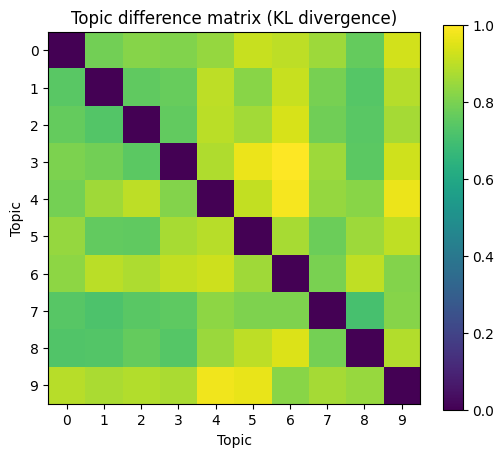

In [7]:
# Calculate topic difference matrix (KL divergence)
# diff returns (matrix, annotation)
diff_matrix, annotation = ldamodel.diff(
    ldamodel,
    distance='kullback_leibler',
    num_words=50    # use top 50 words to compute divergence
)

print("Topic difference matrix shape:", diff_matrix.shape)

# Plot heatmap
plt.figure(figsize=(6, 5))
im = plt.imshow(diff_matrix, cmap="viridis")
plt.colorbar(im)
plt.title("Topic difference matrix (KL divergence)")
plt.xlabel("Topic")
plt.ylabel("Topic")
plt.xticks(range(NUM_TOPICS))
plt.yticks(range(NUM_TOPICS))
plt.show()
